In [1]:
%%writefile custom_transformers.py

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.pipeline import Pipeline

# ==========================================================
# Pipeline: Custom Pipeline with Deduplication
# ==========================================================
class PreprocessingPipelineWithDedup(Pipeline):
    def fit(self, X, y=None, **fit_params):
        if y is not None:
            X_clean, y_clean = self._apply_deduplication(X, y)
            self.y_clean_ = y_clean
            return super().fit(X_clean, y_clean, **fit_params)
        return super().fit(X, y, **fit_params)

    def fit_transform(self, X, y=None, **fit_params):
        if y is not None:
            X_clean, y_clean = self._apply_deduplication(X, y)
            self.y_clean_ = y_clean
            X_transformed = super().fit_transform(X_clean, y_clean, **fit_params)
            return X_transformed
        return super().fit_transform(X, y, **fit_params)

    def transform(self, X, y=None):
        return super().transform(X)

    def _apply_deduplication(self, X, y):
        print(f"[Deduplication] X_train before: {X.shape[0]:,} rows")
        
        train_combined = X.copy()
        train_combined['__target__'] = y.values
        train_deduped = train_combined.drop_duplicates(subset=X.columns.tolist(), keep='first')

        X_clean = train_deduped.drop(columns=['__target__'])
        y_clean = train_deduped['__target__']

        removed = len(X) - len(X_clean)
        print(f"[Deduplication] X_train after:  {X_clean.shape[0]:,} rows")
        print(f"[Deduplication] Removed: {removed} duplicate rows")
        return X_clean, y_clean


# ========================================================== 
# Transformer 1: Datetime Feature Extractor 
# ==========================================================
class DatetimeFeatureExtractor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
        
    def transform(self, X):
        X = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X).copy()
        f2_dt = pd.to_datetime(X['f2'], errors='coerce', format='mixed')
        f3_dt = pd.to_datetime(X['f3'], errors='coerce', format='mixed')
 
        X['duration_minutes'] = (f3_dt - f2_dt).dt.total_seconds() / 60
        X['start_hour']       = f2_dt.dt.hour.astype('float64')
        X['start_month']      = f2_dt.dt.month.astype('float64')
        X['start_dayofweek']  = f2_dt.dt.dayofweek.astype('float64')
        #return X
        return X.drop(columns=['f2', 'f3', 'f13'], errors='ignore')
        
    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.array(input_features)
        return None

# ========================================================== 
# Transformer 2: Bool To Int 
# ==========================================================
class BoolToInt(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
        
    def transform(self, X):
        X = pd.DataFrame(X).copy() if not isinstance(X, pd.DataFrame) else X.copy()
        for col in X.select_dtypes(include='bool').columns:
            X[col] = X[col].astype(int)
        return X
            
    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.array(input_features)
        return None

# ========================================================== 
# Transformer 3: Target Encoder
# ==========================================================
class TargetEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cols, smoothing=10):
        self.cols = cols
        self.smoothing = smoothing
        
    def fit(self, X, y):
        X = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X).copy()
        self.global_mean_ = float(np.mean(y))
        self.encoding_maps_ = {}
 
        for col in self.cols:
            if col not in X.columns:
                continue
            tmp = pd.DataFrame({'cat': X[col].astype(str).values, 'target': np.array(y)})
            stats = tmp.groupby('cat')['target'].agg(['mean', 'count'])
            smoother = stats['count'] / (stats['count'] + self.smoothing)
            smoothed = smoother * stats['mean'] + (1 - smoother) * self.global_mean_
            self.encoding_maps_[col] = smoothed.to_dict()
        return self

    def transform(self, X):
        X = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X).copy()
        for col in self.cols:
            if col not in X.columns:
                continue
            X[col] = X[col].astype(str).map(self.encoding_maps_[col]).fillna(self.global_mean_)
        return X
 
    def get_feature_names_out(self, input_features=None):
        return np.array(input_features) if input_features is not None else None

# ========================================================== 
# Transformer 4: Day / Night Binary Encoder 
# ==========================================================
class DayNightBinaryEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cols):
        self.cols = cols
 
    def fit(self, X, y=None):
        X = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X).copy()
        self.fill_values_ = {}
        for col in self.cols:
            if col in X.columns:
                self.fill_values_[col] = X[col].mode()[0]
        return self

    def transform(self, X):
        X = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X).copy()
        for col in self.cols:
            if col not in X.columns:
                continue
            X[col] = X[col].fillna(self.fill_values_[col])
            X[col] = (X[col].str.strip().str.lower() == 'day').astype(int)
        return X
 
    def get_feature_names_out(self, input_features=None):
        return np.array(input_features) if input_features is not None else None

# ========================================================== 
# Transformer 5: IQR Capper 
# ==========================================================
class IQRCapper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):
        self.factor = factor  # ضریب IQR (استاندارد = 1.5)
        
    def fit(self, X, y=None):
        X_arr = np.array(X, dtype=float)
        self.n_features_ = X_arr.shape[1]
        self.bounds_ = {}
        for i in range(self.n_features_):
            col_data = X_arr[:, i]
            col_data = col_data[~np.isnan(col_data)]  # NaN را نادیده بگیر

            if len(col_data) == 0:
                self.bounds_[i] = {
                    'lower': -np.inf,
                    'upper': np.inf,
                    'q1': np.nan,
                    'q3': np.nan,
                    'iqr': np.nan
                }
                continue

            q1 = np.percentile(col_data, 25)
            q3 = np.percentile(col_data, 75)
            iqr = q3 - q1
            if iqr == 0:
                lower = np.percentile(col_data, 1)
                upper = np.percentile(col_data, 99)

                if lower == upper:
                    self.bounds_[i] = None
                    continue

                self.bounds_[i] = {
                    'lower': lower,
                    'upper': upper,
                    'q1': q1, 'q3': q3, 'iqr': iqr
                }
                #print(f"Feature {i}: IQR=0")
            else:
                self.bounds_[i] = {
                    'lower': q1 - self.factor * iqr,
                    'upper': q3 + self.factor * iqr,
                    'q1': q1, 'q3': q3, 'iqr': iqr
                }
        return self
            
    def transform(self, X):
        X_arr = np.array(X, dtype=float).copy()
        for i in range(self.n_features_):
            if self.bounds_[i] is None:
                continue
            lower = self.bounds_[i]['lower']
            upper = self.bounds_[i]['upper']
            X_arr[:, i] = np.clip(X_arr[:, i], lower, upper)
        return X_arr
            
    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.array(input_features)
        return np.array([f'x{i}' for i in range(self.n_features_)])

# ==========================================================
# Transformer 6: Text Keyword Extractor (Replaces Target Encoding for f8, f9)
# ==========================================================
class TextKeywordExtractor(BaseEstimator, TransformerMixin):
    def __init__(self, text_cols):
        self.text_cols = text_cols

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X).copy()
        
        for col in self.text_cols:
            if col not in X.columns:
                continue
                
            text_data = X[col].astype(str).fillna("missing")
            
            if col == 'f8':
                X['f8_is_highway'] = text_data.str.contains(r'\b(?:I-|US-|[A-Z]{2}-\d+)\b', case=False, na=False).astype(int)
                
                X['f8_is_local_road'] = text_data.str.contains(r'\b(?:St|Ave|Rd|Blvd|Dr|Ln|Way)\b', case=False, na=False).astype(int)
                
                X['f8_is_severe_crash'] = text_data.str.contains(r'\b(?:Crash|Accident|Overturned|Blocked|Stall)\b', case=False, na=False).astype(int)

                X['f8_is_slow_traffic'] = text_data.str.contains(r'\b(?:Slow traffic|Congestion)\b', case=False, na=False).astype(int)
                
            elif col == 'f9':
                X['f9_is_highway_route'] = text_data.str.contains(r'\b(?:I-|US-|[A-Z]{2}-\d+|Fwy|Hwy|Expy)\b', case=False, na=False).astype(int)
            
            X = X.drop(columns=[col], errors='ignore')
            
        return X

    def get_feature_names_out(self, input_features=None):
        return np.array([
            'f8_is_highway', 
            'f8_is_local_road', 
            'f8_is_severe_crash', 
            'f8_is_slow_traffic', 
            'f9_is_highway_route'
        ])

Overwriting custom_transformers.py


In [2]:
from custom_transformers import (
    PreprocessingPipelineWithDedup,
    DatetimeFeatureExtractor,
    BoolToInt,
    TargetEncoder,
    DayNightBinaryEncoder,
    IQRCapper,
    TextKeywordExtractor
)

print("Imported successfully!") 

Imported successfully!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.base import BaseEstimator, TransformerMixin

pd.set_option('display.max_columns', 100)
("Libraries imported successfully")

'Libraries imported successfully'

In [4]:
DATA_PATH = '../data/raw/group_32_train.csv'
df_raw = pd.read_csv(DATA_PATH)

print(f"Shape: {df_raw.shape}")

print("=" * 65)
print("VALIDATION 0 — Initial Data Inspection")
print("=" * 65)
      
print(f"Rows: {len(df_raw):,}  |  Columns: {df_raw.shape[1]}")
print("=" * 65)

print("Data types:")
dtype_df = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'non_null_count': df_raw.notna().sum(),
    'missing_count': df_raw.isna().sum(),
    'missing_percent_%': (df_raw.isna().mean() * 100).round(2),
    'unique_count': df_raw.nunique(dropna=True)
})
dtype_df.index.name = 'feature'
display(dtype_df.sort_values(['dtype', 'missing_percent_%'], ascending=[True, False]))
print("=" * 65)

print("Missing values:")
mv  = df_raw.isnull().sum()
mvp = (df_raw.isnull().mean() * 100).round(2)
mv_df = pd.DataFrame({'count': mv, 'percent_%': mvp})
display(mv_df[mv_df['count'] > 0].sort_values('percent_%', ascending=False))
print("=" * 65)

print(f"Duplicates: {df_raw.duplicated().sum()}")
print("=" * 65)

print("Target distribution:")
target_count = df_raw['y'].value_counts().sort_index()
target_percent = (df_raw['y'].value_counts(normalize=True).sort_index() * 100).round(2)
target_df = pd.DataFrame({
    'count': target_count,
    'percent_%': target_percent
})
display(target_df)

Shape: (100000, 35)
VALIDATION 0 — Initial Data Inspection
Rows: 100,000  |  Columns: 35
Data types:


,dtype,non_null_count,missing_count,missing_percent_%,unique_count
feature,,,,,
f22,bool,100000,0,0.00,2
f23,bool,100000,0,0.00,2
f24,bool,100000,0,0.00,2
f25,bool,100000,0,0.00,2
f26,bool,100000,0,0.00,2
f27,bool,100000,0,0.00,2
f28,bool,100000,0,0.00,2
f29,bool,100000,0,0.00,2
f30,bool,100000,0,0.00,2


Missing values:


,count,percent_%
feature,,
f6,43986,43.99
f20,28431,28.43
f15,25914,25.91
f19,7485,7.48
f18,2272,2.27
f17,2242,2.24
f16,2234,2.23
f21,2230,2.23
f14,2092,2.09


Duplicates: 22
Target distribution:


,count,percent_%
y,,
1,848,0.85
2,79646,79.65
3,16795,16.79
4,2711,2.71


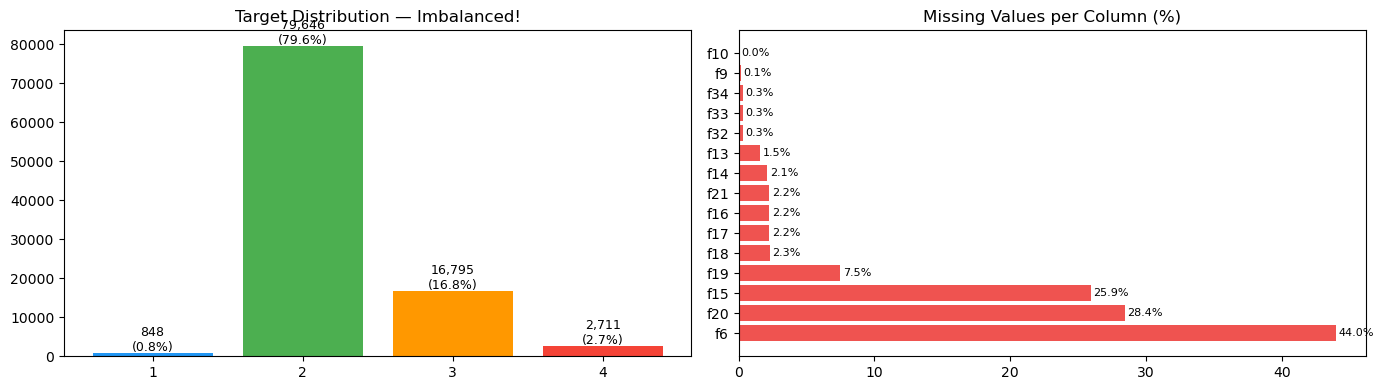

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# توزیع target
cnts = df_raw['y'].value_counts().sort_index()
colors = ['#2196F3','#4CAF50','#FF9800','#F44336']
axes[0].bar(['1','2','3','4'], cnts, color=colors)
axes[0].set_title('Target Distribution — Imbalanced!', fontsize=12)
for i,(c,v) in enumerate(cnts.items()):
    axes[0].text(i, v+500, f'{v:,}\n({v/len(df_raw)*100:.1f}%)', ha='center', fontsize=9)
    
# missing values
mv_plot = (df_raw.isnull().mean()*100).sort_values(ascending=False)
mv_plot = mv_plot[mv_plot > 0]
axes[1].barh(mv_plot.index, mv_plot.values, color='#EF5350')
axes[1].set_title('Missing Values per Column (%)', fontsize=12)
for i,v in enumerate(mv_plot.values):
    axes[1].text(v+0.2, i, f'{v:.1f}%', va='center', fontsize=8)
    
plt.tight_layout() 
plt.show()

In [6]:
# تقسیم بندی داده به train(70%)/validation(15%)/test(15%) 
TARGET = 'y'

X = df_raw.drop(columns=[TARGET])
y = df_raw[TARGET]

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y       # توزیع کلاس‌ها حفظ شود
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.176,
    random_state=42,
    stratify=y_temp
)

n = len(X)
print(f"Train:      {X_train.shape[0]:>7,} rows  ({X_train.shape[0]/n*100:.1f}%)")
print(f"Validation: {X_val.shape[0]:>7,} rows  ({X_val.shape[0]/n*100:.1f}%)")
print(f"Test:       {X_test.shape[0]:>7,} rows  ({X_test.shape[0]/n*100:.1f}%)")

Train:       70,040 rows  (70.0%)
Validation:  14,960 rows  (15.0%)
Test:        15,000 rows  (15.0%)


In [7]:
print("Saving raw split data (before preprocessing)...")

import os
raw_split_path = '../data/raw_split'
os.makedirs(raw_split_path, exist_ok=True)

X_train.to_csv(f'{raw_split_path}/X_train_before.csv', index=False)
X_val.to_csv(f'{raw_split_path}/X_val_before.csv', index=False)
X_test.to_csv(f'{raw_split_path}/X_test_before.csv', index=False)

y_train.to_csv(f'{raw_split_path}/y_train.csv', index=False)
y_val.to_csv(f'{raw_split_path}/y_val.csv', index=False)
y_test.to_csv(f'{raw_split_path}/y_test.csv', index=False)

print("Raw split files saved successfully.")

Saving raw split data (before preprocessing)...
Raw split files saved successfully.


VALIDATION 1 — Split Verification


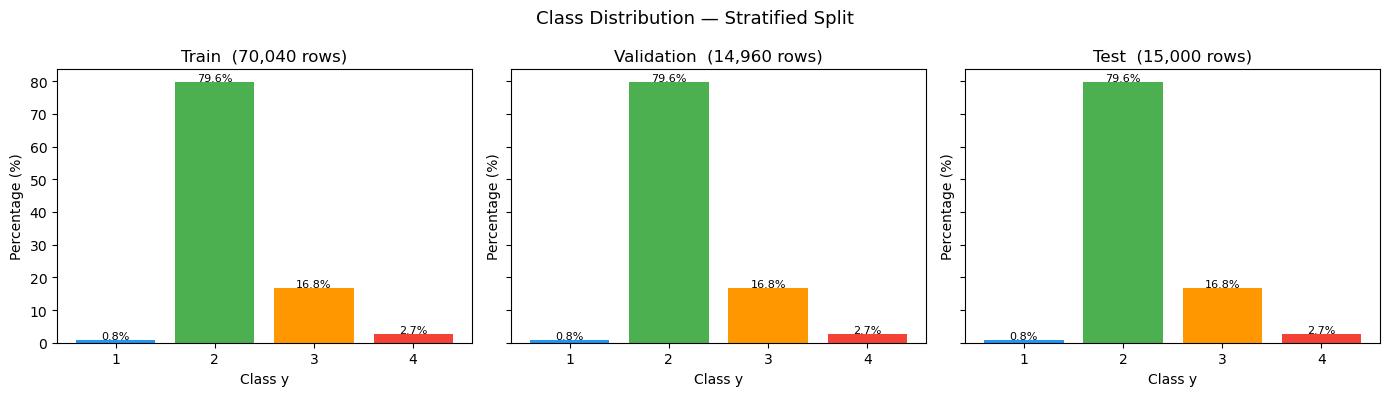

The class distribution is identical in all three sets.


In [8]:
# برای اینکه اطمینان پیدا کنیم تقسیم بندی داده ها صحیح است
print("=" * 65)
print("VALIDATION 1 — Split Verification")
print("=" * 65)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
colors = ['#2196F3','#4CAF50','#FF9800','#F44336']

for ax,(name,yy) in zip(axes,[('Train',y_train),('Validation',y_val),('Test',y_test)]):
    vals = yy.value_counts(normalize=True).sort_index() * 100
    ax.bar(['1','2','3','4'], vals, color=colors)
    ax.set_title(f'{name}  ({len(yy):,} rows)')
    ax.set_xlabel('Class y'); ax.set_ylabel('Percentage (%)')
    for i,v in enumerate(vals):
        ax.text(i, v+0.3, f'{v:.1f}%', ha='center', fontsize=8)
        
plt.suptitle('Class Distribution — Stratified Split', fontsize=13)
plt.tight_layout(); plt.show()
print("The class distribution is identical in all three sets.")

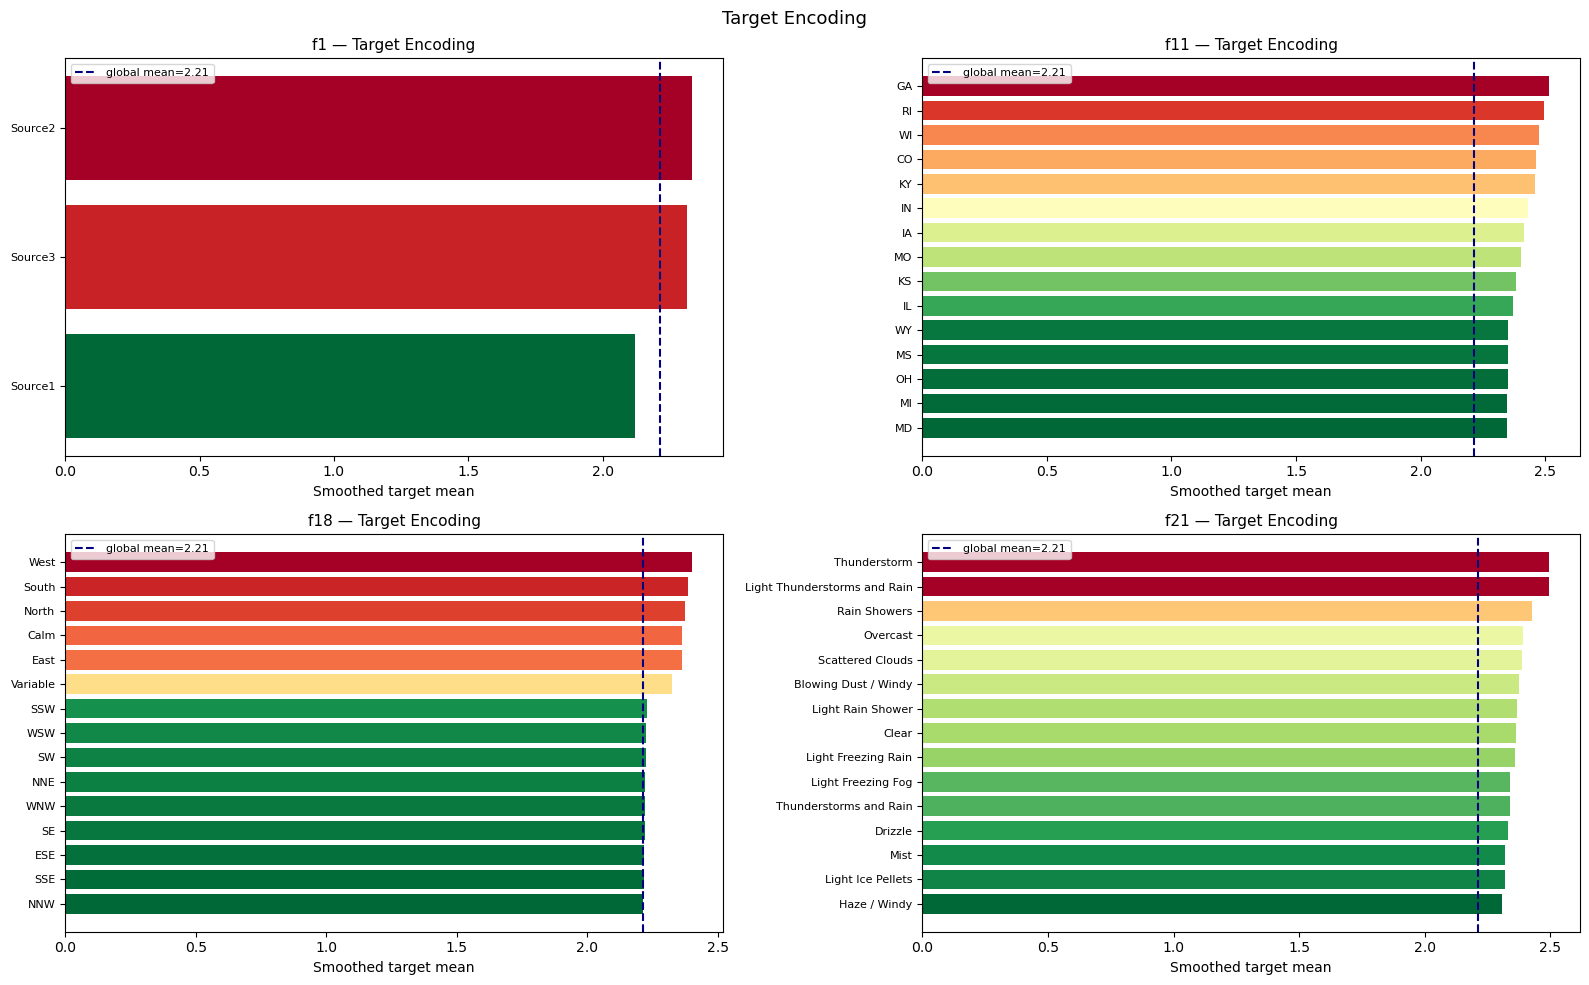

In [9]:
tmp_df = X_train.copy()
tmp_df['y'] = y_train.values
global_mean = tmp_df['y'].mean()
 
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(axes.flat, ['f1', 'f11', 'f18', 'f21']):
    stats = tmp_df.groupby(col)['y'].agg(['mean', 'count']).sort_values('mean')
    smoother = stats['count'] / (stats['count'] + 10)
    smoothed = (smoother * stats['mean'] + (1 - smoother) * global_mean).sort_values()
    if len(smoothed) > 15:
        smoothed = smoothed.tail(15)
    norm = (smoothed.values - smoothed.values.min()) / (smoothed.values.max() - smoothed.values.min() + 1e-9)
    ax.barh(range(len(smoothed)), smoothed.values,
            color=plt.cm.RdYlGn_r(norm))
    ax.axvline(global_mean, color='navy', linestyle='--', linewidth=1.5,
               label=f'global mean={global_mean:.2f}')
    ax.set_yticks(range(len(smoothed)))
    ax.set_yticklabels(smoothed.index, fontsize=8)
    ax.set_title(f'{col} — Target Encoding', fontsize=11)
    ax.set_xlabel('Smoothed target mean')
    ax.legend(fontsize=8)
 
plt.suptitle('Target Encoding', fontsize=13)
plt.tight_layout()
plt.show()

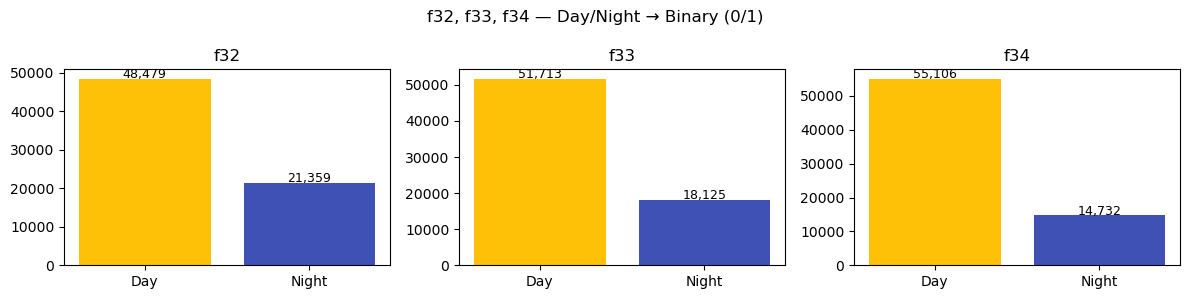

In [10]:
# توزیع Day/Night
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axes, ['f32', 'f33', 'f34']):
    vc = X_train[col].value_counts()
    ax.bar(vc.index, vc.values, color=['#FFC107', '#3F51B5'])
    ax.set_title(f'{col}')
    for i, v in enumerate(vc.values):
        ax.text(i, v+200, f'{v:,}', ha='center', fontsize=9)
plt.suptitle('f32, f33, f34 — Day/Night → Binary (0/1)', fontsize=12)
plt.tight_layout()
plt.show()

In [11]:
print(" Outlier count in TRAIN (IQR method, factor=1.5) ")
num_cols = X_train.select_dtypes(include='number').columns
for col in num_cols:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    out = ((X_train[col] < q1-1.5*iqr) | (X_train[col] > q3+1.5*iqr)).sum()
    if out > 0:
        pct = out / X_train[col].notna().sum() * 100
        print(f"  {col}: {out:,} outliers ({pct:.1f}%)")

 Outlier count in TRAIN (IQR method, factor=1.5) 
  f7: 8,694 outliers (12.4%)
  f14: 412 outliers (0.6%)
  f15: 376 outliers (0.7%)
  f17: 13,516 outliers (19.7%)
  f19: 1,898 outliers (2.9%)
  f20: 4,913 outliers (9.8%)


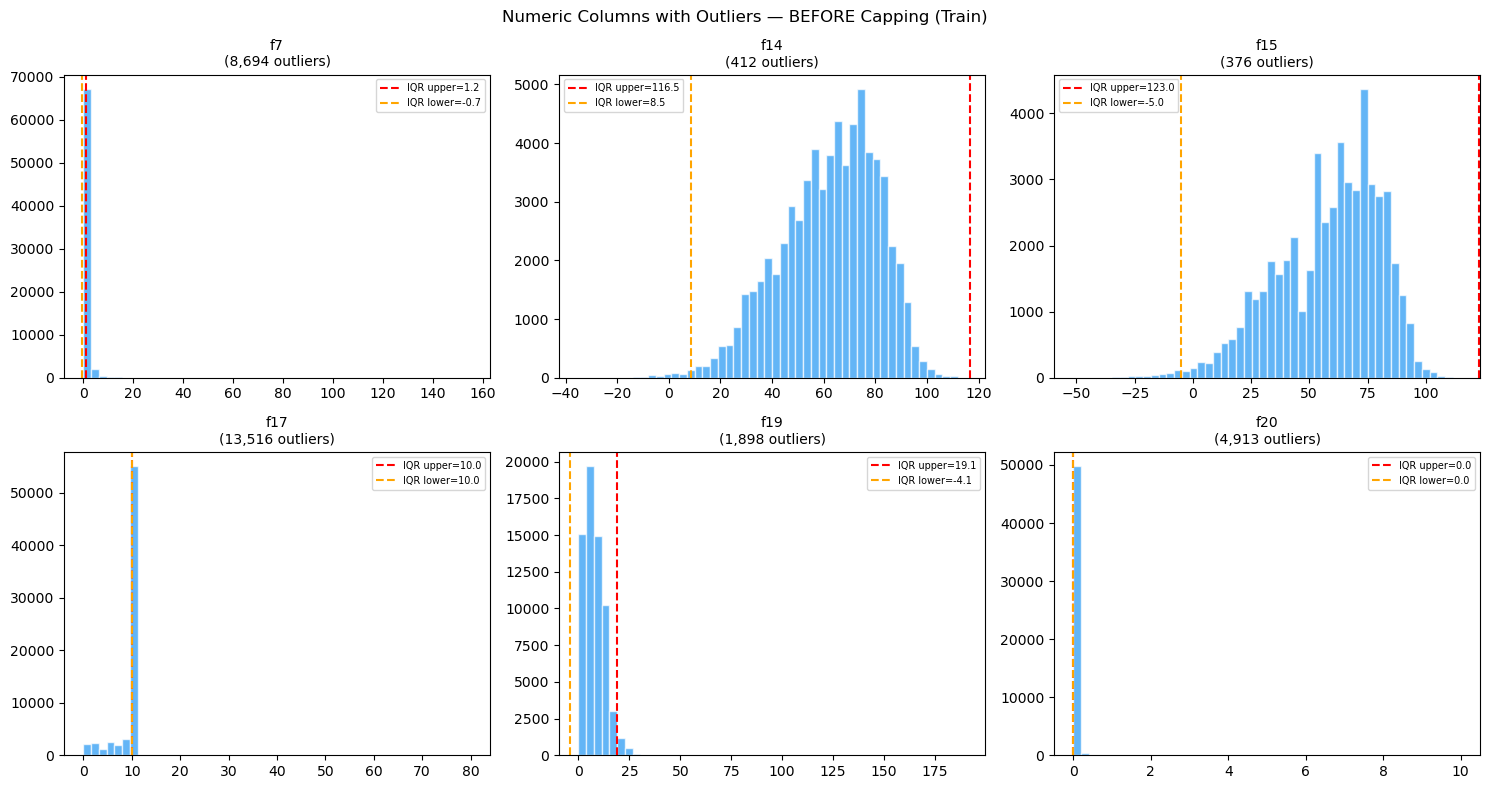

In [12]:
outlier_cols_vis = ['f7', 'f14', 'f15', 'f17', 'f19', 'f20']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), outlier_cols_vis):
    data = X_train[col].dropna()
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr
    n_out = ((data < lower) | (data > upper)).sum()
    ax.hist(data, bins=50, color='#2196F3', alpha=0.7, edgecolor='white')
    ax.axvline(upper, color='red',    linestyle='--', linewidth=1.5, label=f'IQR upper={upper:.1f}')
    ax.axvline(lower, color='orange', linestyle='--', linewidth=1.5, label=f'IQR lower={lower:.1f}')
    ax.set_title(f'{col}\n({n_out:,} outliers)', fontsize=10)
    ax.legend(fontsize=7)
    
plt.suptitle('Numeric Columns with Outliers — BEFORE Capping (Train)', fontsize=12)
plt.tight_layout()
plt.show()

In [13]:
# همه ستون‌های str به جز f2, f3, f13 که datetime هستند و f32, f33, f34 که Day/Night
CATEGORICAL_TE_COLS = ['f10', 'f11', 'f12', 'f18', 'f21', 'f1']
TEXT_REGEX_COLS = ['f8', 'f9']
 
# ستون‌های Day/Night → Binary (0/1) 
DAY_NIGHT_COLS = ['f32', 'f33', 'f34']
 
# ستون‌های عددی با outlier زیاد → IQR Capper + RobustScaler 
NUMERIC_ROBUST_COLS = ['f7', 'f14', 'f15', 'f17', 'f19', 'f20', 'duration_minutes']
 
# ستون‌های عددی با توزیع نرمال‌تر → IQR Capper + StandardScaler 
NUMERIC_STANDARD_COLS = ['f4', 'f5', 'f16']
 
# ستون‌های زمانی گسسته → IQR Capper + MinMaxScaler 
# (0-23, 1-12, 0-6 محدوده مشخص دارند → MinMaxScaler مناسب‌تر است)
NUMERIC_TIME_COLS = ['start_hour', 'start_month', 'start_dayofweek']
 
# ستون‌های boolean → passthrough
BOOL_COLS = ['f22','f23','f24','f25','f26','f27','f28','f29','f30','f31']
 
# f6 که 44% missing دارد → جداگانه با median impute + StandardScaler 
F6_COL = ['f6']
 
print(f"  Categorical (TE):       {len(CATEGORICAL_TE_COLS+TEXT_REGEX_COLS):2d} cols → {CATEGORICAL_TE_COLS + TEXT_REGEX_COLS}")
print(f"  Day/Night (binary):     {len(DAY_NIGHT_COLS):2d} cols → {DAY_NIGHT_COLS}")
print(f"  Numeric (robust):       {len(NUMERIC_ROBUST_COLS):2d} cols → {NUMERIC_ROBUST_COLS}")
print(f"  Numeric (standard):     {len(NUMERIC_STANDARD_COLS):2d} cols → {NUMERIC_STANDARD_COLS}")
print(f"  Numeric (time): {len(NUMERIC_TIME_COLS):2d} cols → {NUMERIC_TIME_COLS}")
print(f"  f6 (high missing):      {len(F6_COL):2d} col  → {F6_COL}")
print(f"  Boolean:               {len(BOOL_COLS):2d} cols → {BOOL_COLS}")
total = (len(CATEGORICAL_TE_COLS+TEXT_REGEX_COLS)+len(DAY_NIGHT_COLS)+len(NUMERIC_ROBUST_COLS)+
         len(NUMERIC_STANDARD_COLS)+len(NUMERIC_TIME_COLS)+len(F6_COL)+len(BOOL_COLS))
print(f"  {'─'*55}")
print(f"  TOTAL:                 {total} cols")

  Categorical (TE):        8 cols → ['f10', 'f11', 'f12', 'f18', 'f21', 'f1', 'f8', 'f9']
  Day/Night (binary):      3 cols → ['f32', 'f33', 'f34']
  Numeric (robust):        7 cols → ['f7', 'f14', 'f15', 'f17', 'f19', 'f20', 'duration_minutes']
  Numeric (standard):      3 cols → ['f4', 'f5', 'f16']
  Numeric (time):  3 cols → ['start_hour', 'start_month', 'start_dayofweek']
  f6 (high missing):       1 col  → ['f6']
  Boolean:               10 cols → ['f22', 'f23', 'f24', 'f25', 'f26', 'f27', 'f28', 'f29', 'f30', 'f31']
  ───────────────────────────────────────────────────────
  TOTAL:                 35 cols


In [14]:
# Pipeline 1: برای ستون‌های عددی با outlier زیاد 
# IQR Capping → Missing Data (median) → RobustScaler
numeric_robust_pipe = Pipeline(steps=[
    ('outlier', IQRCapper(factor=1.5)),             # Noise & Outlier Reduction
    ('imputer', SimpleImputer(strategy='median')),  # Missing Data Handling
    ('scaler',  RobustScaler())                     # Standardization 
])
 
# Pipeline 2: برای ستون‌های عددی نرمال 
# IQR Capping → Missing Data (mean) → StandardScaler (Z-score)
numeric_standard_pipe = Pipeline(steps=[
    ('outlier', IQRCapper(factor=1.5)),             # Noise & Outlier Reduction
    ('imputer', SimpleImputer(strategy='mean')),    # Missing Data Handling
    ('scaler',  StandardScaler())                   # Z-score Standardization
])
 
# Pipeline برای ستون‌های زمانی (0-23, 1-12, 0-6)
# MinMaxScaler چون محدوده مشخص دارند
numeric_time_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  MinMaxScaler())
])
 
# Pipeline برای f6 (44% missing، بدون outlier) 
f6_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])
 
# ColumnTransformer 
column_transformer = ColumnTransformer(
    transformers=[
        ('num_robust',   numeric_robust_pipe,   NUMERIC_ROBUST_COLS),
        ('num_standard', numeric_standard_pipe, NUMERIC_STANDARD_COLS),
        ('cyclic',       numeric_time_pipe,   NUMERIC_TIME_COLS),
        ('f6',           f6_pipe,               F6_COL),
        ('bool',         'passthrough',         BOOL_COLS),
    ],
    remainder='passthrough'  
)
 
print("[✓] All sub-pipelines defined")
print("[✓] ColumnTransformer defined")

[✓] All sub-pipelines defined
[✓] ColumnTransformer defined


In [15]:
# main_pipeline
main_pipeline = PreprocessingPipelineWithDedup([
    ('text_regex', TextKeywordExtractor(text_cols=TEXT_REGEX_COLS)),
    ('target_encoder', TargetEncoder(
        cols=CATEGORICAL_TE_COLS,
        smoothing=10
    )),
    ('datetime_feat', DatetimeFeatureExtractor()),
    ('bool_to_int', BoolToInt()),
    ('day_night', DayNightBinaryEncoder(cols=DAY_NIGHT_COLS)),
    ('col_transformer', column_transformer),
])

print("\nStep 1: Fitting main pipeline on train (Deduplication happens inside)...")
X_train_processed = main_pipeline.fit_transform(X_train, y_train)

y_train_clean = main_pipeline.y_clean_

print("Step 2: Transforming validation...")
X_val_processed = main_pipeline.transform(X_val)

print("Step 3: Transforming test...")
X_test_processed = main_pipeline.transform(X_test)

# تأیید Deduplication
print(f"\n[✓] Deduplication (Handled inside Pipeline)")
print(f"  Remaining duplicates in original X_train: {X_train.duplicated().sum()}")
print(f"  Final clean X_train rows passed to models: {X_train_processed.shape[0]:,}")

print(f"\n[✓] Pipeline complete!")
print(f"  X_train: {X_train_processed.shape}")
print(f"  X_val:   {X_val_processed.shape}")
print(f"  X_test:  {X_test_processed.shape}")


Step 1: Fitting main pipeline on train (Deduplication happens inside)...
[Deduplication] X_train before: 70,040 rows
[Deduplication] X_train after:  70,024 rows
[Deduplication] Removed: 16 duplicate rows
Step 2: Transforming validation...
Step 3: Transforming test...

[✓] Deduplication (Handled inside Pipeline)
  Remaining duplicates in original X_train: 16
  Final clean X_train rows passed to models: 70,024

[✓] Pipeline complete!
  X_train: (70024, 38)
  X_val:   (14960, 38)
  X_test:  (15000, 38)


In [16]:
import joblib
import os

os.makedirs('../models', exist_ok=True)

# ذخیره pipeline کامل (شامل TargetEncoder + همه مراحل preprocessing)
joblib.dump(main_pipeline, '../models/main_preprocess_pipeline.pkl')

print("[✓] Pipeline saved to ../models/main_preprocess_pipeline.pkl")

[✓] Pipeline saved to ../models/main_preprocess_pipeline.pkl


In [17]:
ct_cols = main_pipeline.named_steps['col_transformer'].get_feature_names_out()
 
X_train_df = pd.DataFrame(X_train_processed, columns=ct_cols)
X_val_df   = pd.DataFrame(X_val_processed,   columns=ct_cols)
X_test_df  = pd.DataFrame(X_test_processed,  columns=ct_cols)
 
print("=" * 65)
print("VALIDATION 3 — Post-Processing Checks")
print("=" * 65)
 
print(f"\n[CHECK 1] Missing values:")
print(f"  Train:      {X_train_df.isnull().sum().sum()}  ← باید 0 باشد")
print(f"  Validation: {X_val_df.isnull().sum().sum()}    ← باید 0 باشد")
print(f"  Test:       {X_test_df.isnull().sum().sum()}   ← باید 0 باشد")
 
print(f"\n[CHECK 2] Shape:")
print(f"  X_train: {X_train_df.shape[0]:,} × {X_train_df.shape[1]} features")
print(f"  X_val:   {X_val_df.shape[0]:,} × {X_val_df.shape[1]} features")
print(f"  X_test:  {X_test_df.shape[0]:,} × {X_test_df.shape[1]} features")
 
print(f"\n[CHECK 3] Feature names:")
for c in ct_cols:
    print(f"  {c}")

X_train_df.to_csv('../data/processed/X_train_processed.csv', index=False)
X_val_df.to_csv('../data/processed/X_val_processed.csv', index=False)
X_test_df.to_csv('../data/processed/X_test_processed.csv', index=False)
y_train_clean.to_csv('../data/processed/y_train.csv', index=False)
y_val.to_csv('../data/processed/y_val.csv', index=False)
y_test.to_csv('../data/processed/y_test.csv', index=False)

print("=" * 65)
print("[✓] Processed datasets saved to ../data/processed/")
print("=" * 65)

VALIDATION 3 — Post-Processing Checks

[CHECK 1] Missing values:
  Train:      0  ← باید 0 باشد
  Validation: 0    ← باید 0 باشد
  Test:       0   ← باید 0 باشد

[CHECK 2] Shape:
  X_train: 70,024 × 38 features
  X_val:   14,960 × 38 features
  X_test:  15,000 × 38 features

[CHECK 3] Feature names:
  num_robust__f7
  num_robust__f14
  num_robust__f15
  num_robust__f17
  num_robust__f19
  num_robust__f20
  num_robust__duration_minutes
  num_standard__f4
  num_standard__f5
  num_standard__f16
  cyclic__start_hour
  cyclic__start_month
  cyclic__start_dayofweek
  f6__f6
  bool__f22
  bool__f23
  bool__f24
  bool__f25
  bool__f26
  bool__f27
  bool__f28
  bool__f29
  bool__f30
  bool__f31
  remainder__f1
  remainder__f10
  remainder__f11
  remainder__f12
  remainder__f18
  remainder__f21
  remainder__f32
  remainder__f33
  remainder__f34
  remainder__f8_is_highway
  remainder__f8_is_local_road
  remainder__f8_is_severe_crash
  remainder__f8_is_slow_traffic
  remainder__f9_is_highway_route

In [18]:
# CHECK 4: آمار کامل
print("[CHECK 4] Statistical summary:")
X_train_df.describe().round(3)

[CHECK 4] Statistical summary:


,num_robust__f7,num_robust__f14,num_robust__f15,num_robust__f17,num_robust__f19,num_robust__f20,num_robust__duration_minutes,num_standard__f4,num_standard__f5,num_standard__f16,cyclic__start_hour,cyclic__start_month,cyclic__start_dayofweek,f6__f6,bool__f22,bool__f23,bool__f24,bool__f25,bool__f26,bool__f27,bool__f28,bool__f29,bool__f30,bool__f31,remainder__f1,remainder__f10,remainder__f11,remainder__f12,remainder__f18,remainder__f21,remainder__f32,remainder__f33,remainder__f34,remainder__f8_is_highway,remainder__f8_is_local_road,remainder__f8_is_severe_crash,remainder__f8_is_slow_traffic,remainder__f9_is_highway_route
count,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.0,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000,70024.000
mean,0.555,-0.084,-0.140,-0.954,0.108,0.004,0.205,-0.000,0.000,0.000,0.536,0.522,0.432,-0.000,0.013,0.114,0.003,0.009,0.000,0.026,0.028,0.001,0.149,0.0,2.214,2.207,2.213,2.214,2.214,2.213,0.695,0.741,0.790,0.660,0.733,0.807,0.091,0.434
std,0.901,0.716,1.004,2.322,0.950,0.021,0.789,1.000,1.000,1.000,0.237,0.331,0.300,1.000,0.112,0.318,0.053,0.095,0.007,0.160,0.165,0.032,0.356,0.0,0.104,0.124,0.100,0.000,0.073,0.086,0.460,0.438,0.408,0.474,0.442,0.394,0.288,0.496
min,-0.064,-2.135,-3.526,-9.500,-1.400,0.000,-0.779,-2.293,-1.717,-2.780,0.000,0.000,0.000,-2.285,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,2.122,1.934,2.049,2.214,2.133,2.082,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,-0.064,-0.538,-0.526,0.000,-0.400,0.000,-0.462,-0.555,-1.297,-0.701,0.348,0.182,0.167,-0.074,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,2.122,2.109,2.137,2.214,2.157,2.135,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000
50%,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-0.073,0.397,0.051,0.565,0.545,0.500,0.306,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,2.122,2.184,2.164,2.214,2.214,2.209,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000
75%,0.936,0.462,0.474,0.000,0.600,0.000,0.538,0.764,0.824,0.847,0.739,0.818,0.667,0.546,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,2.331,2.282,2.260,2.214,2.225,2.247,1.000,1.000,1.000,1.000,1.000,1.000,0.000,1.000
max,2.436,1.962,2.789,0.000,2.420,0.180,2.038,2.503,1.513,1.555,1.000,1.000,1.000,1.698,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.0,2.331,2.809,2.514,2.214,2.400,2.493,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


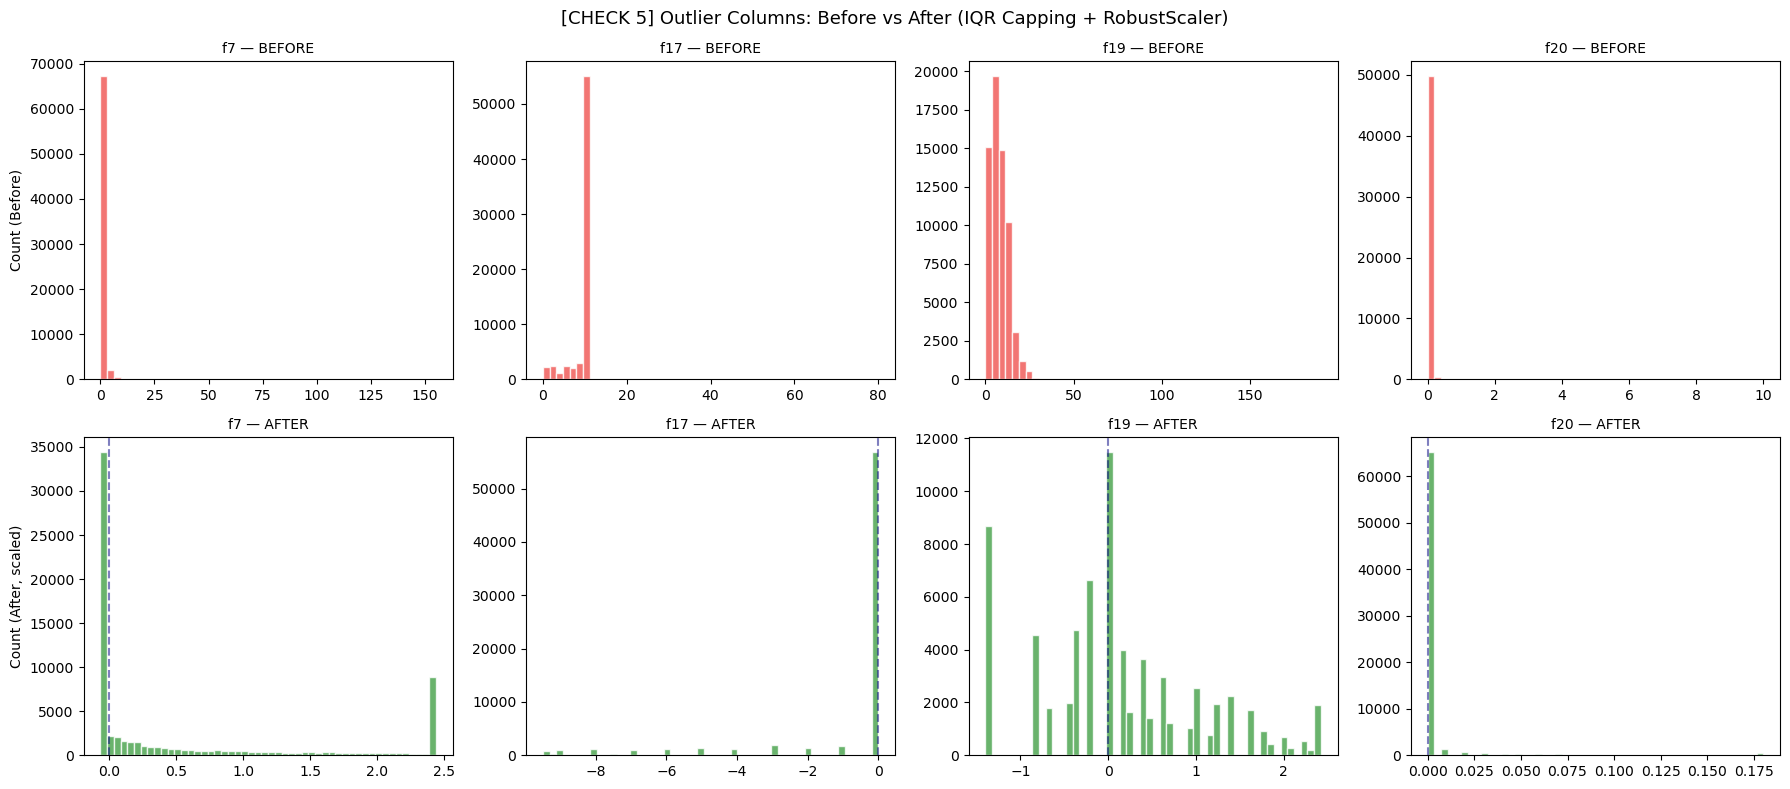

In [19]:
# CHECK 5: نمودار قبل و بعد از outlier capping
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
outlier_vis = ['f7', 'f17', 'f19', 'f20']
 
for i, col in enumerate(outlier_vis):
    axes[0, i].hist(X_train[col].dropna(), bins=50, color='#EF5350', alpha=0.8, edgecolor='white')
    axes[0, i].set_title(f'{col} — BEFORE', fontsize=10)
 
    col_after = f'num_robust__{col}'
    if col_after in X_train_df.columns:
        axes[1, i].hist(X_train_df[col_after], bins=50, color='#43A047', alpha=0.8, edgecolor='white')
        axes[1, i].set_title(f'{col} — AFTER', fontsize=10)
        axes[1, i].axvline(0, color='navy', linestyle='--', alpha=0.5)
 
axes[0,0].set_ylabel('Count (Before)')
axes[1,0].set_ylabel('Count (After, scaled)')
plt.suptitle('[CHECK 5] Outlier Columns: Before vs After (IQR Capping + RobustScaler)', fontsize=13)
plt.tight_layout()
plt.show()

In [20]:
#خلاصه کامل preprocessing

# محاسبه تعداد ردیف‌های حذف شده
removed_rows = len(X_train) - X_train_processed.shape[0]

print('=' * 68)
print('PREPROCESSING SUMMARY — Group 32 | Section 3.4')
print('=' * 68)
print()
print('Flow :')
print(' Raw Data → Split → Dedup(Inside Pipeline) → Missing → Outlier → Standardization → Clean')
print()
print(f' Raw dataset: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} cols')
print(f' Train: {X_train_processed.shape[0]:,} | Val: {X_val.shape[0]:,} | Test: {X_test.shape[0]:,}')
print()
print(' [SPLIT] Stratified 70/15/15 by y')
print()
print(' [DATETIME] feature :')
print(' duration_minutes, start_hour, start_month, start_dayofweek')
print()
print(' [MISSING DATA]')
print(' Numeric (outlier cols): SimpleImputer(median)')
print(' Numeric (normal cols): SimpleImputer(mean)')
print(' f6 (44% missing): SimpleImputer(median)')
print(' Cyclic cols: SimpleImputer(median)')
print(' Categorical (TE): NaN → string "nan" → global_mean in TargetEncoder')
print(' Day/Night: most_frequent in DayNightBinaryEncoder')
print()
print(' [OUTLIER — IQR Capping, factor=1.5]')
print(' f7, f14, f15, f17, f19, f20, duration_minutes')
print()
print(' [STANDARDIZATION]')
print(' Numeric (outlier): RobustScaler (median/IQR-based)')
print(' Numeric (normal): StandardScaler (Z-score)')
print(' Cyclic (0-23 etc): MinMaxScaler')
print(' f6: StandardScaler')
print(' Categorical: Target Encoding')
print(' Day/Night: Binary 0/1')
print(' Boolean: passthrough (0/1)')
print()
print(f' [DEDUP] Removed {removed_rows} duplicate rows from train (Handled inside Pipeline)')
print()
print(f' OUTPUT: {X_train_processed.shape[1]} features | 0 missing | 0 duplicates ✅')
print('=' * 68)

PREPROCESSING SUMMARY — Group 32 | Section 3.4

Flow :
 Raw Data → Split → Dedup(Inside Pipeline) → Missing → Outlier → Standardization → Clean

 Raw dataset: 100,000 rows × 35 cols
 Train: 70,024 | Val: 14,960 | Test: 15,000

 [SPLIT] Stratified 70/15/15 by y

 [DATETIME] feature :
 duration_minutes, start_hour, start_month, start_dayofweek

 [MISSING DATA]
 Numeric (outlier cols): SimpleImputer(median)
 Numeric (normal cols): SimpleImputer(mean)
 f6 (44% missing): SimpleImputer(median)
 Cyclic cols: SimpleImputer(median)
 Categorical (TE): NaN → string "nan" → global_mean in TargetEncoder
 Day/Night: most_frequent in DayNightBinaryEncoder

 [OUTLIER — IQR Capping, factor=1.5]
 f7, f14, f15, f17, f19, f20, duration_minutes

 [STANDARDIZATION]
 Numeric (outlier): RobustScaler (median/IQR-based)
 Numeric (normal): StandardScaler (Z-score)
 Cyclic (0-23 etc): MinMaxScaler
 f6: StandardScaler
 Categorical: Target Encoding
 Day/Night: Binary 0/1
 Boolean: passthrough (0/1)

 [DEDUP] Remove